# Bangladesh Road Accidents 2021–2026: Analysis

Uses the cleaned tables in `data/processed/` (built by `01_data_cleaning.ipynb`). All figures are Road Safety
Foundation (RSF) counts of accidents reported in the media.

1. Deaths by year
2. Deaths by vehicle type
3. Deaths by division
4. Time of year (month, season, Eid) and time of day
5. Key findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

DATA = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Chart palette (light mode)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CONTEXT = "#c3c2b7"   # de-emphasised bars
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SURFACE = "#fcfcfb"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.edgecolor": CONTEXT, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 22, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "figure.dpi": 110,
})


def titled(ax, title, subtitle):
    ax.set_title(title)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

In [2]:
monthly = pd.read_csv(DATA / "monthly_national.csv")
annual = pd.read_csv(DATA / "annual_national.csv")
vehicle = pd.read_csv(DATA / "vehicle_deaths.csv")
division = pd.read_csv(DATA / "division.csv")
time_of_day = pd.read_csv(DATA / "time_of_day.csv")
eid = pd.read_csv(DATA / "eid_periods.csv")
population = pd.read_csv("../data/raw/division_population_2022.csv")

full_years = annual[annual["coverage"] == "full year"].copy()
full_years["year"] = full_years["year"].astype(int)

## 1. Deaths by year

RSF's annual reports give complete counts for 2021–2025. 2026 is still in progress, so it is compared with 2025
separately below, using only the months reported in both years.

In [3]:
yearly = full_years.set_index("year")[["accidents", "deaths", "injuries", "deaths_per_accident"]].copy()
yearly["deaths_per_day"] = (yearly["deaths"] / 365).round(1)
yearly["deaths_change_pct"] = (100 * yearly["deaths"].pct_change()).round(1)
yearly["accidents_change_pct"] = (100 * yearly["accidents"].pct_change()).round(1)
yearly.astype({"accidents": int, "deaths": int, "injuries": int})

,accidents,deaths,injuries,deaths_per_accident,deaths_per_day,deaths_change_pct,accidents_change_pct
year,,,,,,,
2021,5371,6284,7468,1.17,17.2,NaN,NaN
2022,6829,7713,12615,1.13,21.1,22.7,27.1
2023,6911,6524,11407,0.94,17.9,-15.4,1.2
2024,6927,7294,12019,1.05,20.0,11.8,0.2
2025,7584,7359,16476,0.97,20.2,0.9,9.5


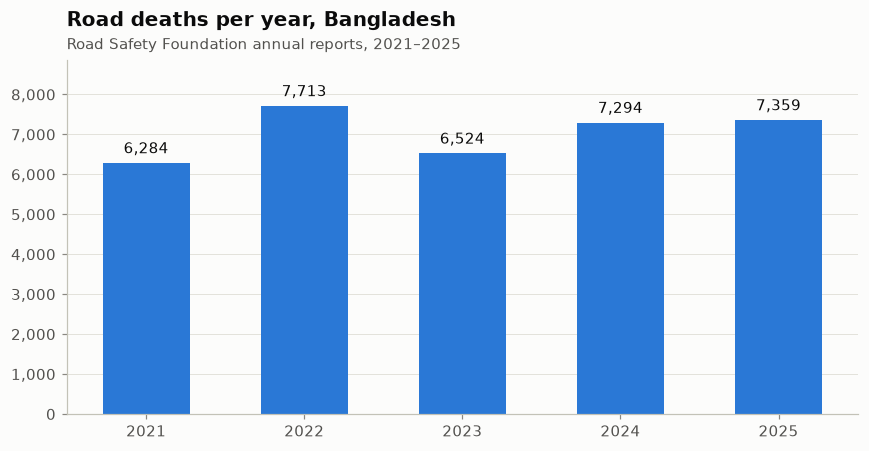

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(yearly.index, yearly["deaths"], width=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in yearly["deaths"]], padding=4, color=INK, fontsize=10)
ax.set_ylim(0, yearly["deaths"].max() * 1.15)
ax.yaxis.set_major_formatter(thousands)
ax.grid(axis="x", visible=False)
ax.set_xticks(yearly.index)
titled(ax, "Road deaths per year, Bangladesh", "Road Safety Foundation annual reports, 2021–2025")
save(fig, "01_deaths_per_year")

Accidents, deaths and injuries indexed to 2021 = 100, so all three can share one axis:

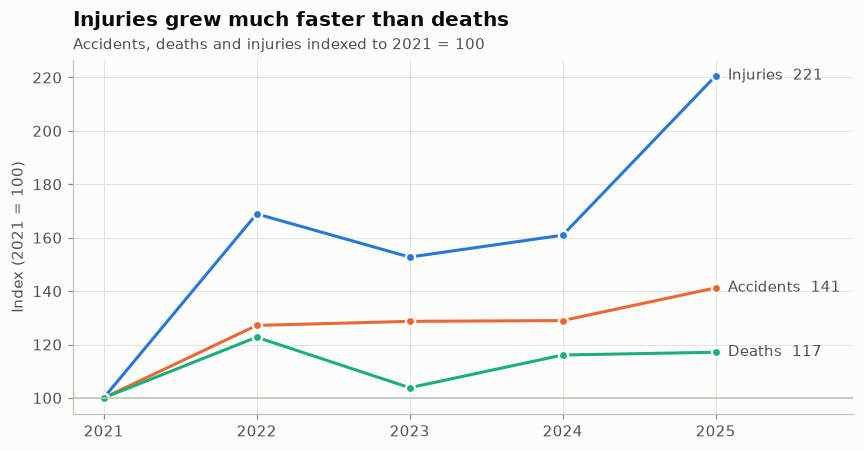

In [5]:
indexed = 100 * yearly[["accidents", "deaths", "injuries"]] / yearly[["accidents", "deaths", "injuries"]].iloc[0]

fig, ax = plt.subplots(figsize=(8, 4.2))
for col, color in zip(["injuries", "accidents", "deaths"], [BLUE, ORANGE, AQUA]):
    ax.plot(indexed.index, indexed[col], color=color, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.5)
    ax.annotate(f"{col.capitalize()}  {indexed[col].iloc[-1]:.0f}", (indexed.index[-1], indexed[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9.5)
ax.axhline(100, color=CONTEXT, lw=1)
ax.set_xticks(indexed.index)
ax.set_xlim(2020.8, 2025.9)
ax.set_ylabel("Index (2021 = 100)")
titled(ax, "Injuries grew much faster than deaths", "Accidents, deaths and injuries indexed to 2021 = 100")
save(fig, "02_indexed_trend")

### 2026 so far vs 2025 (same months)

Like-for-like: only months that have an RSF report in **both** 2025 and 2026.

In [6]:
m = monthly[monthly["reported"]]
both = sorted(set(m.loc[m["year"] == 2025, "month"]) & set(m.loc[m["year"] == 2026, "month"]))
ytd = (
    m[m["year"].isin([2025, 2026]) & m["month"].isin(both)]
    .groupby("year")[["accidents", "deaths", "injuries"]].sum()
)
ytd.loc["change_pct"] = (100 * (ytd.loc[2026] / ytd.loc[2025] - 1)).round(1)
print("Months compared:", [pd.Timestamp(2000, mo, 1).strftime("%b") for mo in both])
ytd

Months compared: ['Jan', 'Mar', 'Apr', 'Jun', 'Jul', 'Aug', 'Sep']


,accidents,deaths,injuries
year,,,
2025,3830.0,3759.0,7651.0
2026,3483.0,3181.0,6652.0
change_pct,-9.1,-15.4,-13.1


### Who dies

The annual reports also break deaths down by victim group:

In [7]:
victims = full_years.set_index("year")[["deaths", "pedestrian_deaths", "women_deaths", "children_deaths"]]
shares = (100 * victims[["pedestrian_deaths", "women_deaths", "children_deaths"]].div(victims["deaths"], axis=0)).round(1)
shares.columns = ["pedestrians_%", "women_%", "children_%"]
victims.join(shares)

,deaths,pedestrian_deaths,women_deaths,children_deaths,pedestrians_%,women_%,children_%
year,,,,,,,
2021,6284.0,1523.0,927.0,734.0,24.2,14.8,11.7
2022,7713.0,NaN,1061.0,1143.0,NaN,13.8,14.8
2023,6524.0,NaN,974.0,1128.0,NaN,14.9,17.3
2024,7294.0,1535.0,893.0,1152.0,21.0,12.2,15.8
2025,7359.0,1564.0,962.0,1008.0,21.3,13.1,13.7


## 2. Deaths by vehicle type

### 2.1 Motorcycles, year by year

Motorcycle deaths are the one vehicle category RSF reports every year.

,deaths,motorcycle_deaths,motorcycle_death_share_pct
year,,,
2021,6284.0,2214.0,35.2
2022,7713.0,3091.0,40.1
2023,6524.0,2487.0,38.1
2024,7294.0,2609.0,35.8
2025,7359.0,2671.0,36.3


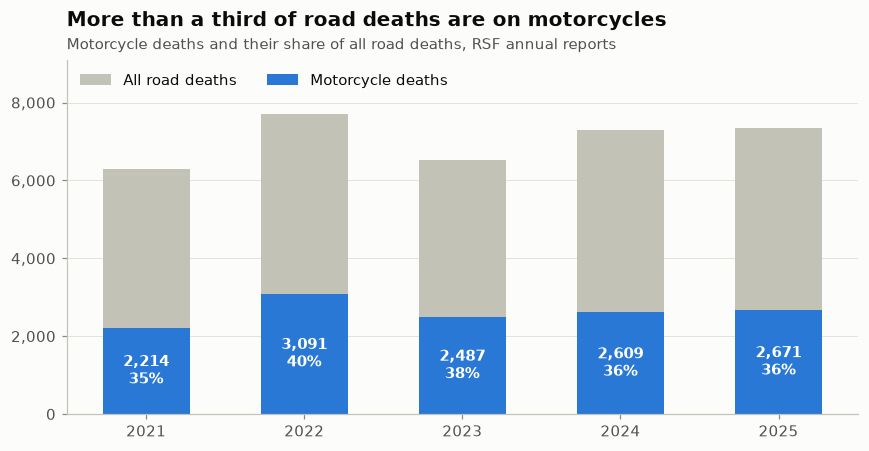

In [8]:
moto = full_years.set_index("year")[["deaths", "motorcycle_deaths", "motorcycle_death_share_pct"]]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(moto.index, moto["deaths"], width=0.55, color=CONTEXT, label="All road deaths")
bars = ax.bar(moto.index, moto["motorcycle_deaths"], width=0.55, color=BLUE, label="Motorcycle deaths")
ax.bar_label(bars, labels=[f"{d:,.0f}\n{s:.0f}%" for d, s in zip(moto["motorcycle_deaths"], moto["motorcycle_death_share_pct"])],
             label_type="center", color="white", fontsize=9.5, fontweight="bold")
ax.yaxis.set_major_formatter(thousands)
ax.grid(axis="x", visible=False)
ax.set_xticks(moto.index)
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.0))
ax.set_ylim(0, moto["deaths"].max() * 1.18)
titled(ax, "More than a third of road deaths are on motorcycles", "Motorcycle deaths and their share of all road deaths, RSF annual reports")
save(fig, "03_motorcycle_deaths")
moto

### 2.2 All vehicle types

The full 7-category split appears in the **2024 annual report** and in **14 monthly reports** (Nov 2023 – Sep 2026).
RSF counts pedestrians separately, so the 7 vehicle categories add up to all deaths **except pedestrians**. In 2024
that was 5,759 vehicle deaths + 1,535 pedestrians = 7,294. Shares below are of the non-pedestrian deaths.

In [9]:
cats = ["Motorcycle", "Three-wheeler", "Truck / pickup / goods", "Bus", "Car / microbus", "Local vehicle", "Bicycle / rickshaw"]

v_month = vehicle[vehicle["period_type"] == "month"]
full_months = v_month.groupby(["year", "month"])["vehicle_type"].nunique().loc[lambda s: s == 7].index
v_full = v_month.set_index(["year", "month"]).loc[full_months].reset_index()

monthly_share = (
    v_full.pivot_table(index=["year", "month"], columns="vehicle_type", values="deaths")
    .pipe(lambda d: 100 * d.div(d.sum(axis=1), axis=0))
    .mean()
)
annual_2024 = vehicle[(vehicle["period_type"] == "year") & (vehicle["year"] == 2024)].set_index("vehicle_type")["deaths"]
share_2024 = 100 * annual_2024 / annual_2024.sum()

mix = pd.DataFrame({"2024 annual report": share_2024, f"Average of {len(full_months)} monthly reports": monthly_share}).loc[cats].round(1)
mix["2024 deaths"] = annual_2024.loc[cats].astype(int)
mix

,2024 annual report,Average of 14 monthly reports,2024 deaths
vehicle_type,,,
Motorcycle,45.3,47.0,2609
Three-wheeler,24.2,24.7,1392
Truck / pickup / goods,8.7,9.3,499
Bus,6.4,7.2,369
Car / microbus,6.3,4.3,363
Local vehicle,5.7,4.7,331
Bicycle / rickshaw,3.4,2.8,196


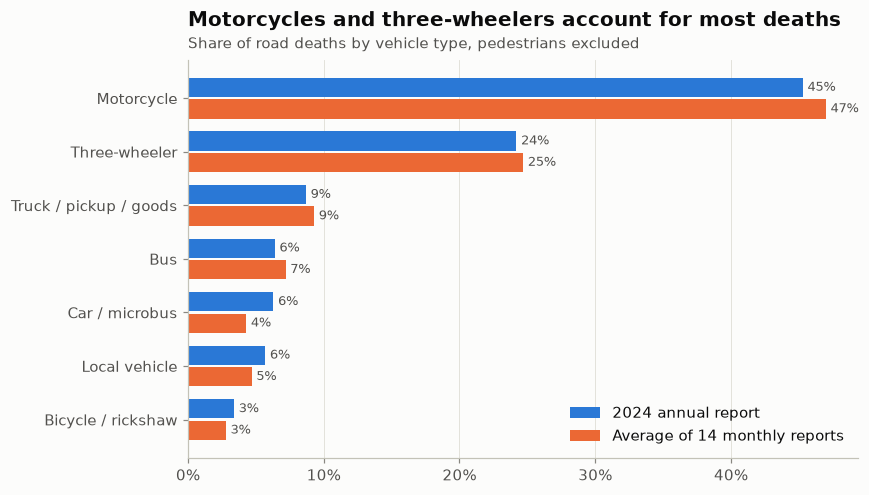

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(cats))
h = 0.36
cols = list(mix.columns[:2])
for i, (col, color) in enumerate(zip(cols, [BLUE, ORANGE])):
    b = ax.barh(y + (i - 0.5) * (h + 0.04), mix[col], height=h, color=color, label=col)
    ax.bar_label(b, fmt="%.0f%%", padding=3, color=INK2, fontsize=8.5)
ax.set_yticks(y, cats)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
titled(ax, "Motorcycles and three-wheelers account for most deaths", "Share of road deaths by vehicle type, pedestrians excluded")
save(fig, "04_vehicle_mix")

### 2.3 Motorcycle share month by month

For every month where both the total and motorcycle deaths are known:

      count  mean
year             
2021      6  37.8
2022      8  37.7
2023      8  34.4
2024      4  40.0
2025     11  36.0
2026      7  34.3


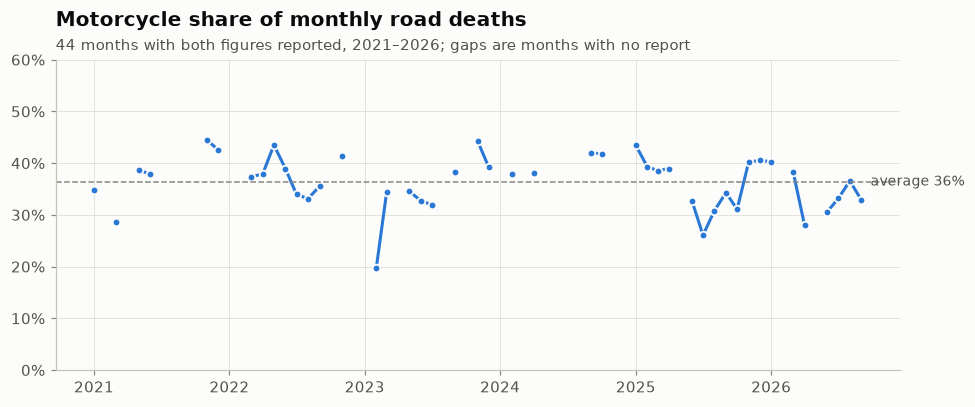

In [11]:
moto_m = (
    vehicle[(vehicle["period_type"] == "month") & (vehicle["vehicle_type"] == "Motorcycle")]
    .merge(monthly[["year", "month", "deaths"]].rename(columns={"deaths": "total_deaths"}), on=["year", "month"])
    .dropna(subset=["total_deaths"])
)
moto_m["share_pct"] = 100 * moto_m["deaths"] / moto_m["total_deaths"]
moto_m["date"] = pd.to_datetime(dict(year=moto_m["year"], month=moto_m["month"].astype(int), day=1))
# Put on a full monthly calendar so the line breaks where a month is missing instead of bridging the gap.
moto_line = moto_m.set_index("date")["share_pct"].reindex(pd.date_range("2021-01-01", "2026-09-01", freq="MS"))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(moto_line.index, moto_line, color=BLUE, lw=2, marker="o", ms=5, mec=SURFACE, mew=1.2)
avg = moto_m["share_pct"].mean()
ax.axhline(avg, color=MUTED, lw=1, ls="--")
ax.annotate(f"average {avg:.0f}%", (moto_line.index[-1], avg), xytext=(6, 0), textcoords="offset points",
            va="center", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 60)
titled(ax, "Motorcycle share of monthly road deaths", f"{len(moto_m)} months with both figures reported, 2021–2026; gaps are months with no report")
save(fig, "05_motorcycle_share_monthly")
print(moto_m.groupby("year")["share_pct"].agg(["count", "mean"]).round(1))

## 3. Deaths by division

### 3.1 Share of accidents vs share of population

Eight monthly reports (Jun–Aug 2022, Aug–Nov 2025, Jun 2026) include the full 8-division table. RSF gives it as
each division's share of the month's accidents. Averaging the eight and setting them against each division's share
of the 2022 census population shows which divisions have more accidents than their population would predict.

In [12]:
DIVISIONS = ["Dhaka", "Chattogram", "Rajshahi", "Khulna", "Rangpur", "Mymensingh", "Sylhet", "Barishal"]

shares = division[(division["measure"] == "share_pct") & (division["period_type"] == "month")]
complete = shares.groupby(["year", "month"])["division"].nunique().loc[lambda s: s == 8].index
shares = shares.set_index(["year", "month"]).loc[complete].reset_index()
# Each table should add up to ~100%; rescale the small rounding differences away.
shares["share_pct"] = 100 * shares["value"] / shares.groupby(["year", "month"])["value"].transform("sum")

div_table = (
    shares.groupby("division")["share_pct"].agg(accident_share_pct="mean", min="min", max="max", tables="count")
    .join(population.set_index("division")["pop_2022"])
)
div_table["population_share_pct"] = 100 * div_table["pop_2022"] / div_table["pop_2022"].sum()
div_table["accidents_vs_population"] = div_table["accident_share_pct"] / div_table["population_share_pct"]
div_table = div_table.loc[DIVISIONS].round({"accident_share_pct": 1, "min": 1, "max": 1, "population_share_pct": 1,
                                            "accidents_vs_population": 2})
div_table

,accident_share_pct,min,max,tables,pop_2022,population_share_pct,accidents_vs_population
division,,,,,,,
Dhaka,26.9,24.6,31.6,8,44215107,26.8,1.00
Chattogram,20.5,16.5,23.7,8,33202326,20.1,1.02
Rajshahi,15.4,11.5,19.3,8,20353119,12.3,1.25
Khulna,11.0,6.9,14.3,8,17416645,10.5,1.04
Rangpur,9.0,6.0,11.3,8,17610956,10.7,0.85
Mymensingh,6.0,4.0,7.1,8,12225498,7.4,0.81
Sylhet,5.0,2.8,9.1,8,11034863,6.7,0.74
Barishal,6.2,3.7,9.0,8,9100102,5.5,1.12


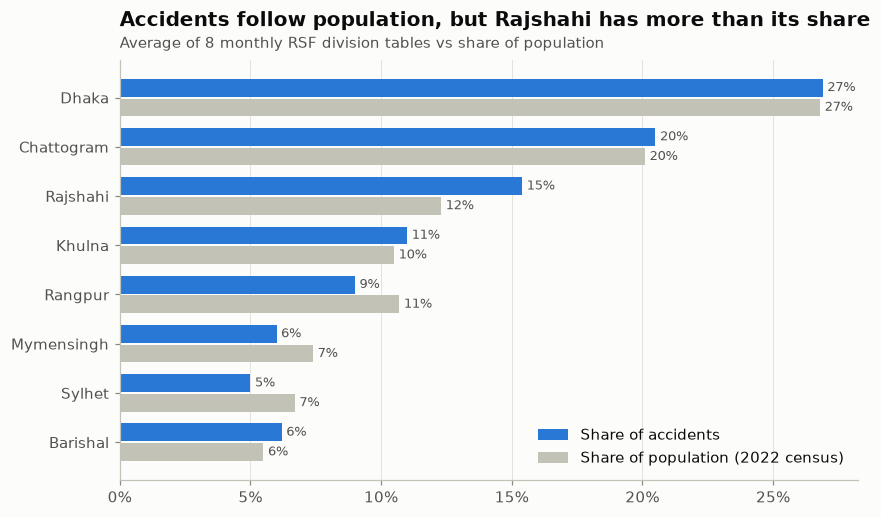

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(DIVISIONS))
h = 0.36
for i, (col, color, label) in enumerate([("accident_share_pct", BLUE, "Share of accidents"),
                                          ("population_share_pct", CONTEXT, "Share of population (2022 census)")]):
    b = ax.barh(y + (i - 0.5) * (h + 0.04), div_table[col], height=h, color=color, label=label)
    ax.bar_label(b, fmt="%.0f%%", padding=3, color=INK2, fontsize=8.5)
ax.set_yticks(y, DIVISIONS)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
titled(ax, "Accidents follow population, but Rajshahi has more than its share",
       f"Average of {len(complete)} monthly RSF division tables vs share of population")
save(fig, "06_division_share")

### 3.2 Highest and lowest division each month

Most monthly reports name only the division with the **most** and the **fewest** accidents. For each month the
reported divisions are ranked on one measure: accidents if at least two divisions have an accident count,
otherwise deaths.

In [14]:
counts = division[(division["period_type"] == "month") & division["measure"].isin(["accidents", "deaths"])]
counts = counts.pivot_table(index=["year", "month", "division"], columns="measure", values="value").reset_index()


def rank_month(g):
    measure = "accidents" if g["accidents"].notna().sum() >= 2 else "deaths"
    g = g.dropna(subset=[measure])
    if len(g) < 2:
        return None
    return pd.Series({"highest": g.loc[g[measure].idxmax(), "division"], "lowest": g.loc[g[measure].idxmin(), "division"]})


ranked = counts.groupby(["year", "month"])[["division", "accidents", "deaths"]].apply(rank_month).dropna()
highest = ranked["highest"].value_counts()
lowest = ranked["lowest"].value_counts()
named = pd.DataFrame({"times_highest": highest, "times_lowest": lowest}).fillna(0).astype(int)
named = named.loc[[d for d in DIVISIONS if d in named.index]]
print("Months compared:", len(ranked))
named

Months compared: 26


,times_highest,times_lowest
Dhaka,25,0
Chattogram,1,0
Rangpur,0,2
Mymensingh,0,2
Sylhet,0,12
Barishal,0,10


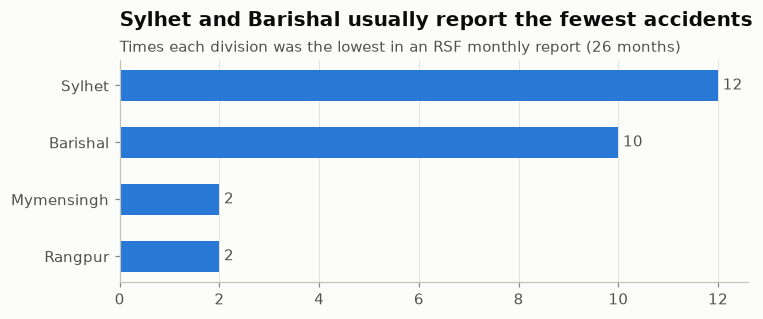

In [15]:
low = named["times_lowest"].loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
b = ax.barh(low.index, low.values, color=BLUE, height=0.55)
ax.bar_label(b, padding=3, color=INK2)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
titled(ax, "Sylhet and Barishal usually report the fewest accidents",
       f"Times each division was the lowest in an RSF monthly report ({len(ranked)} months)")
save(fig, "07_division_lowest")

### 3.3 Dhaka division over time

Dhaka division is reported in nearly every month, and also in four of the annual reports, so its share of national
deaths can be tracked.

One monthly figure looks wrong. For August 2022 the article says "242 people were killed in 127 accidents" in Dhaka
division. 127 accidents matches the report's 27.7% accident share, but 242 deaths would be 47% of the month's
deaths, so it is probably a typo in the article. The value stays in the data as published, and the summary below
uses the median so that one month does not distort it.

In [16]:
dhaka_year = (
    division[(division["division"] == "Dhaka") & (division["period_type"] == "year") & (division["measure"] == "deaths")]
    .set_index("year")["value"].rename("dhaka_deaths").to_frame()
    .join(full_years.set_index("year")["deaths"])
)
dhaka_year["dhaka_share_pct"] = (100 * dhaka_year["dhaka_deaths"] / dhaka_year["deaths"]).round(1)

dhaka_m = counts[(counts["division"] == "Dhaka")].dropna(subset=["deaths"]).merge(
    monthly[["year", "month", "deaths"]].rename(columns={"deaths": "total"}), on=["year", "month"]).dropna(subset=["total"])
dhaka_m["share_pct"] = 100 * dhaka_m["deaths"] / dhaka_m["total"]
print(f"Monthly: Dhaka division's median share of deaths was {dhaka_m['share_pct'].median():.1f}% "
      f"over {len(dhaka_m)} months (range {dhaka_m['share_pct'].min():.0f}–{dhaka_m['share_pct'].max():.0f}%)")
print(f"Dhaka division's share of population: {div_table.loc['Dhaka', 'population_share_pct']:.1f}%")
dhaka_year

Monthly: Dhaka division's median share of deaths was 26.5% over 30 months (range 22–47%)
Dhaka division's share of population: 26.8%


,dhaka_deaths,deaths,dhaka_share_pct
year,,,
2021,1545.0,6284.0,24.6
2022,2044.0,7713.0,26.5
2024,1840.0,7294.0,25.2
2025,2018.0,7359.0,27.4


## 4. Time of year

### 4.1 Every month at a glance

Deaths per day for each reported month (dividing by days in the month makes February comparable). Blank cells are
months with no RSF report.

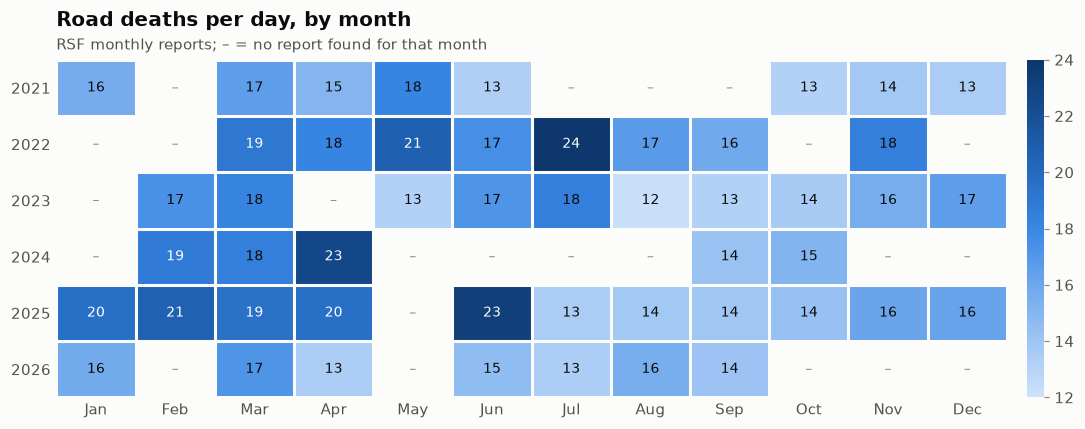

In [17]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
grid = monthly.pivot(index="year", columns="month", values="deaths_per_day").reindex(columns=range(1, 13))

fig, ax = plt.subplots(figsize=(10, 4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
cmap.set_bad(SURFACE)
im = ax.imshow(np.ma.masked_invalid(grid.values), cmap=cmap, aspect="auto", vmin=12, vmax=24)
for (r, c), v in np.ndenumerate(grid.values):
    if not np.isnan(v):
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 18.5 else INK)
    else:
        ax.text(c, r, "–", ha="center", va="center", fontsize=9, color=MUTED)
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(grid)), grid.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, 12), minor=True)
ax.set_yticks(np.arange(-0.5, len(grid)), minor=True)
ax.grid(which="minor", color=SURFACE, lw=2)
ax.tick_params(which="both", length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED, labelcolor=INK2)
titled(ax, "Road deaths per day, by month", "RSF monthly reports; – = no report found for that month")
save(fig, "08_monthly_heatmap")

### 4.2 Which months are worst?

Years differ in their overall level, so each month is compared with **its own year's average** (seasonal
index: 1.10 means 10% more deaths per day than that year's average month). The index is then averaged across years.

In [18]:
rep = monthly[monthly["reported"]].copy()
rep["index"] = rep["deaths_per_day"] / rep.groupby("year")["deaths_per_day"].transform("mean")
season_idx = rep.groupby("month")["index"].agg(["mean", "count"]).reindex(range(1, 13))
season_idx.index = MONTHS
season_idx.round(2).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,1.08,1.12,1.1,1.06,1.06,1.05,1.04,0.88,0.85,0.86,0.96,0.97
count,3.00,3.00,6.0,5.00,3.00,5.00,4.00,4.00,5.00,4.00,4.00,3.00


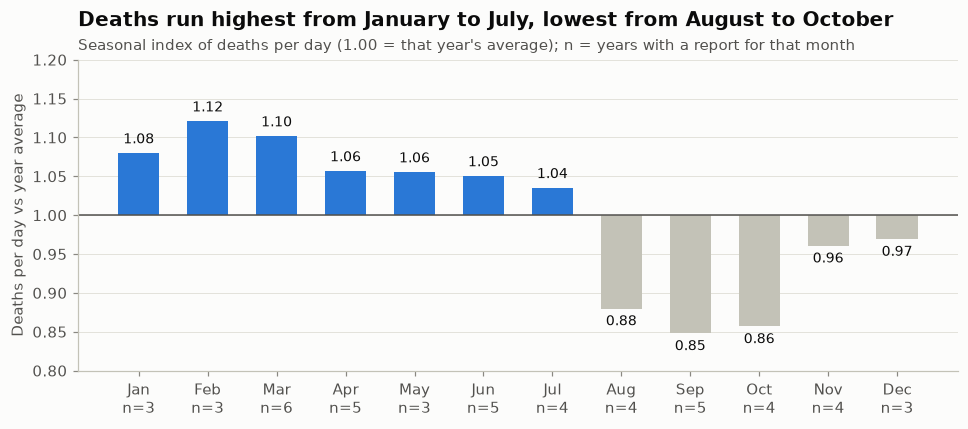

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = [BLUE if v >= 1 else CONTEXT for v in season_idx["mean"]]
b = ax.bar(season_idx.index, season_idx["mean"] - 1, bottom=1, color=colors, width=0.6)
ax.axhline(1, color=INK2, lw=1)
for x, v in enumerate(season_idx["mean"]):
    ax.text(x, v + (0.008 if v >= 1 else -0.008), f"{v:.2f}", ha="center", va="bottom" if v >= 1 else "top",
            fontsize=9, color=INK)
ax.set_xticks(range(12), [f"{m}\nn={n}" for m, n in zip(MONTHS, season_idx["count"])])
ax.set_ylim(0.8, 1.2)
ax.set_ylabel("Deaths per day vs year average")
ax.grid(axis="x", visible=False)
titled(ax, "Deaths run highest from January to July, lowest from August to October",
       "Seasonal index of deaths per day (1.00 = that year's average); n = years with a report for that month")
save(fig, "09_seasonal_index")

Grouped into Bangladesh's meteorological seasons (Bangladesh Meteorological Department):

In [20]:
SEASONS = {12: "Winter (Dec–Feb)", 1: "Winter (Dec–Feb)", 2: "Winter (Dec–Feb)",
           3: "Pre-monsoon (Mar–May)", 4: "Pre-monsoon (Mar–May)", 5: "Pre-monsoon (Mar–May)",
           6: "Monsoon (Jun–Sep)", 7: "Monsoon (Jun–Sep)", 8: "Monsoon (Jun–Sep)", 9: "Monsoon (Jun–Sep)",
           10: "Post-monsoon (Oct–Nov)", 11: "Post-monsoon (Oct–Nov)"}
rep["season"] = rep["month"].map(SEASONS)
by_season = (
    rep.groupby("season")
    .agg(months=("index", "count"), seasonal_index=("index", "mean"), mean_deaths_per_day=("deaths_per_day", "mean"))
    .loc[list(dict.fromkeys(SEASONS[m] for m in [12, 3, 6, 10]))]
    .round(2)
)
by_season

,months,seasonal_index,mean_deaths_per_day
season,,,
Winter (Dec–Feb),9,1.06,17.11
Pre-monsoon (Mar–May),14,1.08,17.84
Monsoon (Jun–Sep),18,0.95,15.80
Post-monsoon (Oct–Nov),8,0.91,15.00


### 4.3 Eid travel

Before each Eid, millions of people travel from the cities to their home districts by bus, launch, train and
motorcycle. RSF reports the deaths for each Eid travel window. These counts are compiled the same way as the monthly
reports, so the fair baseline is the average deaths per day across that year's **monthly** reports, not the annual
report (which runs 11–15% higher, see the cleaning notebook):

In [21]:
rep_days = pd.to_datetime(dict(year=rep["year"], month=rep["month"], day=1)).dt.days_in_month
baseline = (rep["deaths"].groupby(rep["year"]).sum() / rep_days.groupby(rep["year"]).sum()).rename("year_avg_per_day")
eid_cmp = eid.dropna(subset=["deaths_per_day"]).merge(baseline, left_on="year", right_index=True, how="left")
eid_cmp["eid_vs_year_pct"] = (100 * (eid_cmp["deaths_per_day"] / eid_cmp["year_avg_per_day"] - 1)).round(0)
eid_cmp["label"] = eid_cmp["festival"].str.replace("Eid-ul-", "") + " " + eid_cmp["year"].astype(str)
eid_cmp = eid_cmp.sort_values(["year", "festival"], ascending=[True, False])
eid_cmp[["label", "days", "deaths", "deaths_per_day", "year_avg_per_day", "eid_vs_year_pct"]].round(1)

,label,days,deaths,deaths_per_day,year_avg_per_day,eid_vs_year_pct
0,Azha 2021,11.0,207.0,18.8,14.9,26.0
3,Fitr 2023,14.0,285.0,20.4,15.5,31.0
5,Fitr 2024,15.0,367.0,24.5,17.8,37.0
7,Fitr 2025,11.0,249.0,22.6,17.3,31.0
6,Azha 2025,12.0,312.0,26.0,17.3,51.0
8,Azha 2026,13.0,281.0,21.6,14.9,45.0


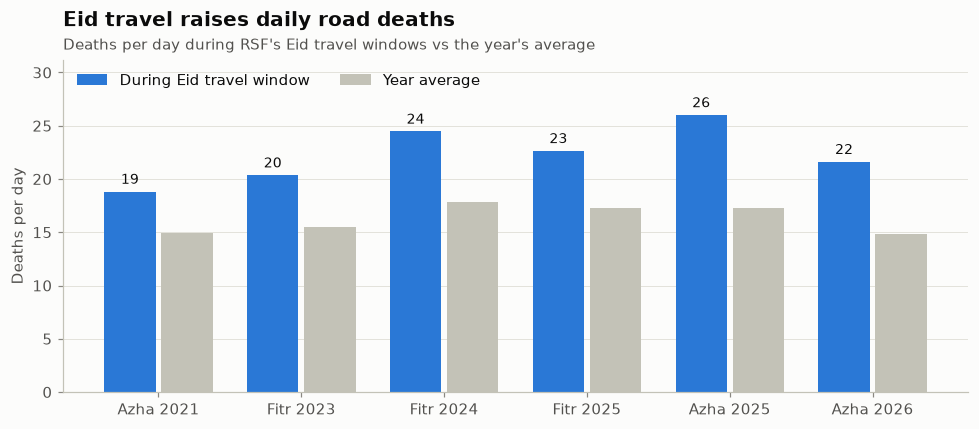

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(eid_cmp))
w = 0.36
b1 = ax.bar(x - w / 2 - 0.02, eid_cmp["deaths_per_day"], width=w, color=BLUE, label="During Eid travel window")
b2 = ax.bar(x + w / 2 + 0.02, eid_cmp["year_avg_per_day"], width=w, color=CONTEXT, label="Year average")
ax.bar_label(b1, labels=[f"{v:.0f}" for v in eid_cmp["deaths_per_day"]], padding=3, fontsize=9, color=INK)
ax.set_xticks(x, eid_cmp["label"])
ax.set_ylabel("Deaths per day")
ax.set_ylim(0, eid_cmp["deaths_per_day"].max() * 1.2)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
titled(ax, "Eid travel raises daily road deaths", "Deaths per day during RSF's Eid travel windows vs the year's average")
save(fig, "10_eid")

### 4.4 Time of day

Some monthly reports give the share of accidents by time of day. RSF does not always use the same bands (some
reports split out dawn and dusk), so only the four main bands that appear in most reports are averaged:

In [23]:
tod = time_of_day.copy()
main_bands = ["morning", "noon", "afternoon", "night"]
tod_summary = tod[tod["time_band"].isin(main_bands)].groupby("time_band")["share_pct"].agg(["mean", "count"]).loc[main_bands].round(1)
tod_summary

,mean,count
time_band,,
morning,29.2,7
noon,18.9,3
afternoon,16.8,6
night,20.1,6


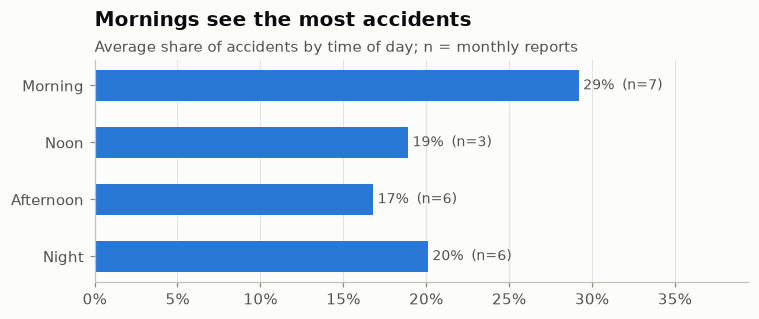

In [24]:
fig, ax = plt.subplots(figsize=(7, 3))
b = ax.barh([s.capitalize() for s in tod_summary.index], tod_summary["mean"], color=BLUE, height=0.55)
ax.bar_label(b, labels=[f"{v:.0f}%  (n={n})" for v, n in zip(tod_summary["mean"], tod_summary["count"])],
             padding=3, color=INK2, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, tod_summary["mean"].max() * 1.35)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
titled(ax, "Mornings see the most accidents", "Average share of accidents by time of day; n = monthly reports")
save(fig, "11_time_of_day")

## 5. Key findings

**By year**
- Road deaths rose from **6,284 in 2021 to 7,359 in 2025** (+17%), peaking at **7,713 in 2022**. In 2025 that was
  about **20 deaths a day**.
- Injuries more than doubled (**7,468 → 16,476**, +121%) and accidents rose 41%, while deaths per accident fell
  from 1.17 to 0.97. More accidents are being reported, and a smaller share of them are fatal.
- **2026 is running lower.** In the seven months reported in both years, deaths are down **15%** and accidents
  down **9%** compared with 2025.

**By vehicle**
- **Motorcycles cause 35–40% of all road deaths every year** (2,214 in 2021 → 2,671 in 2025). If pedestrians are
  left out, motorcycles account for nearly **half** of all deaths.
- **Three-wheelers** (CNG, easy-bike, auto-rickshaw) come second with about a **quarter** of non-pedestrian deaths.
  Buses account for only 6–7%.
- **Pedestrians** make up about **21%** of deaths (2024–2025), down from 24% in 2021. More than **1,000 children**
  were killed in every year from 2022 to 2025.

**By division**
- Accidents broadly **follow population**. Dhaka division has about 27% of accidents and 27% of the population, and
  is the highest division in **25 of 26** monthly reports.
- **Rajshahi** has about **1.25×** its population share of accidents. **Sylhet** has the lowest relative rate (about
  0.75×) and is the division with the fewest accidents in 12 of 26 reports, followed by Barishal (10).

**Time of year**
- Deaths per day run **above average from January to July** (Feb +12%, Mar +10%) and are **lowest in
  August–October** (12–15% below average). The pre-monsoon season (Mar–May) is the worst and the post-monsoon
  season (Oct–Nov) the safest.
- **Eid travel** windows have **26–51% more deaths per day** than the year's normal rate.
- **Mornings** see the largest share of accidents (about 29%).

**Caveats**
- RSF counts accidents reported in the **media**, so the true toll is higher. The WHO's modelled estimate for 2021
  is **31,578 deaths**, about five times RSF's 6,284 (see `data/raw/deadly_roads/national_yearly.csv`).
- 20 of 69 months have no report. The monthly pattern rests on 3–6 years per calendar month, so treat the seasonal
  differences as indicative, not precise.
- Full division and vehicle tables exist for only some months (8 and 14 reports respectively).